In [ ]:
import pandas as pd


testfile = pd.read_csv('/content/Cian_Relax2.csv')
RawTp9 = testfile["RAW_TP9"] #gets column
RawAf7 = testfile["RAW_AF7"]
RawAf7 = testfile["RAW_AF8"]
RAWTp10  = testfile["RAW_TP10"]

rawData = testfile[['RAW_TP9', 'RAW_AF7', 'RAW_AF8', 'RAW_TP10']]
rawData
# print(testfile.to_string())
# print(rawData.loc[2]) #gets row

,RAW_TP9,RAW_AF7,RAW_AF8,RAW_TP10
0,NaN,NaN,NaN,NaN
1,783.69965,782.49084,789.74360,807.87550
2,832.45420,791.75824,792.96704,813.91943
3,813.91943,798.20514,790.14655,794.57874
4,751.46520,801.02563,787.72894,780.07324
...,...,...,...,...
29957,882.41760,751.06226,711.57510,824.79850
29958,816.73990,750.65936,713.58970,804.24910
29959,762.74725,733.33330,711.97800,785.71430
29960,790.54944,743.00366,705.12823,796.59340


#Downsampling

The csv here is recorded at a 256Hz refresh rate, meaning the sampling size is 256. We want to be able to downsample for when we get to the DEAP dataset as that data is 512Hz and we want to have options in our program.



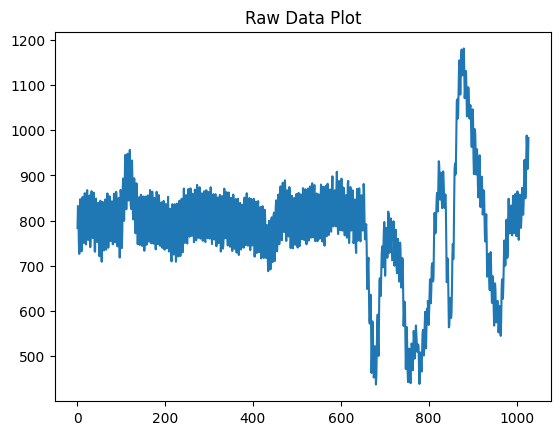

In [ ]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
rawDataSmall = rawData.head(1028)
tp9Small = RawTp9.head(1028)
# plot = rawDataSmall.plot(title="Raw Data Plot")
plot = tp9Small.plot(title="Raw Data Plot")


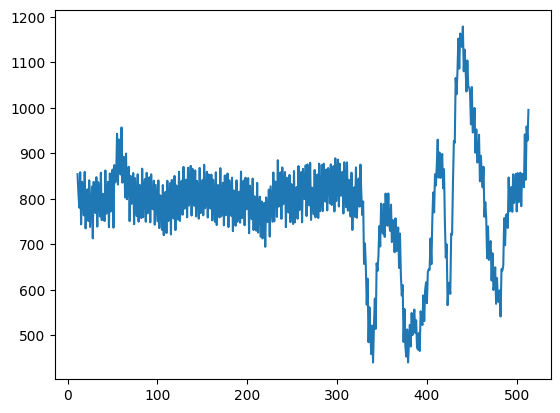

In [ ]:
from scipy.signal import decimate

tp9_clean = pd.to_numeric(tp9Small, errors='coerce').interpolate()
downsampled = decimate(tp9_clean,2, ftype='fir')
plt.plot(downsampled)




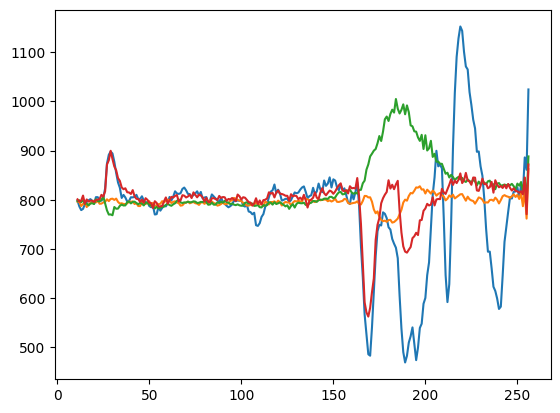

In [ ]:
for col in rawDataSmall.columns:
  small = rawData[col].head(1028)
  small_clean = pd.to_numeric(small, errors='coerce').interpolate()
  downsampled = decimate(small_clean,4, ftype='fir')
  plt.plot(downsampled)


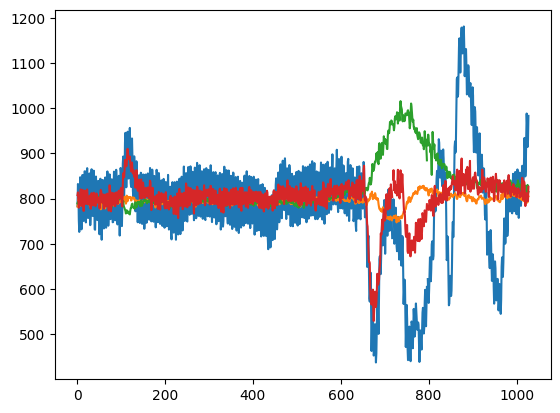

In [ ]:
  plt.plot(rawData.head(1028))


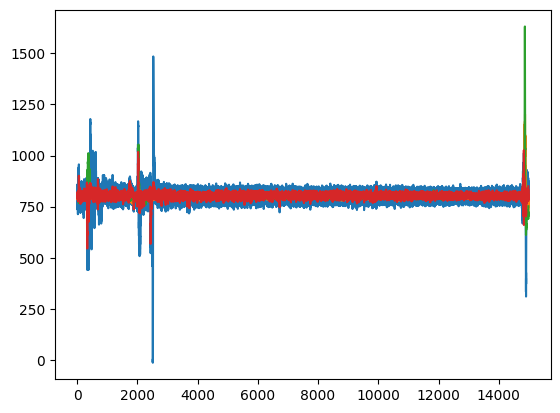

In [ ]:
for col in rawDataSmall.columns:
  small = rawData[col]
  small_clean = pd.to_numeric(small, errors='coerce').interpolate()
  downsampled = decimate(small_clean,2, ftype='fir')
  plt.plot(downsampled)

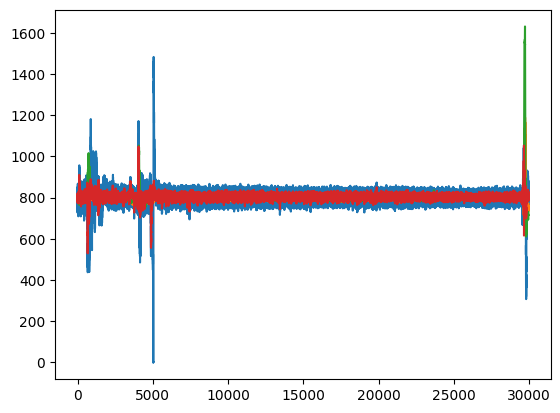

In [ ]:
  plt.plot(rawData)

In [ ]:
!pip install mne


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 50.7 MB/s eta 0:00:00


In [ ]:
import mne

# Path to your .bdf file
file_path = "/content/s02.bdf"

# Load the raw EEG data
raw = mne.io.read_raw_bdf(file_path, preload=True)

Extracting EDF parameters from /content/s02.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...


/tmp/ipython-input-1580405940.py:7: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_bdf(file_path, preload=True)


Reading 0 ... 494591  =      0.000 ...   965.998 secs...


In [ ]:
raw_eeg = raw.copy()
eeg_data, times = raw_eeg.get_data(return_times=True)
raw_eeg = raw.copy().pick('eeg')

32


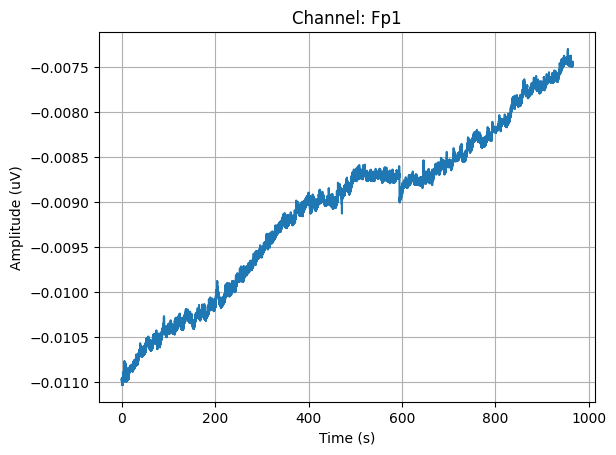

In [ ]:
plt.plot(times, eeg_data[1])  #plot first EEG channel
plt.title(f"Channel: {raw_eeg.ch_names[0]}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (uV)")
plt.grid(True)
plt.show()

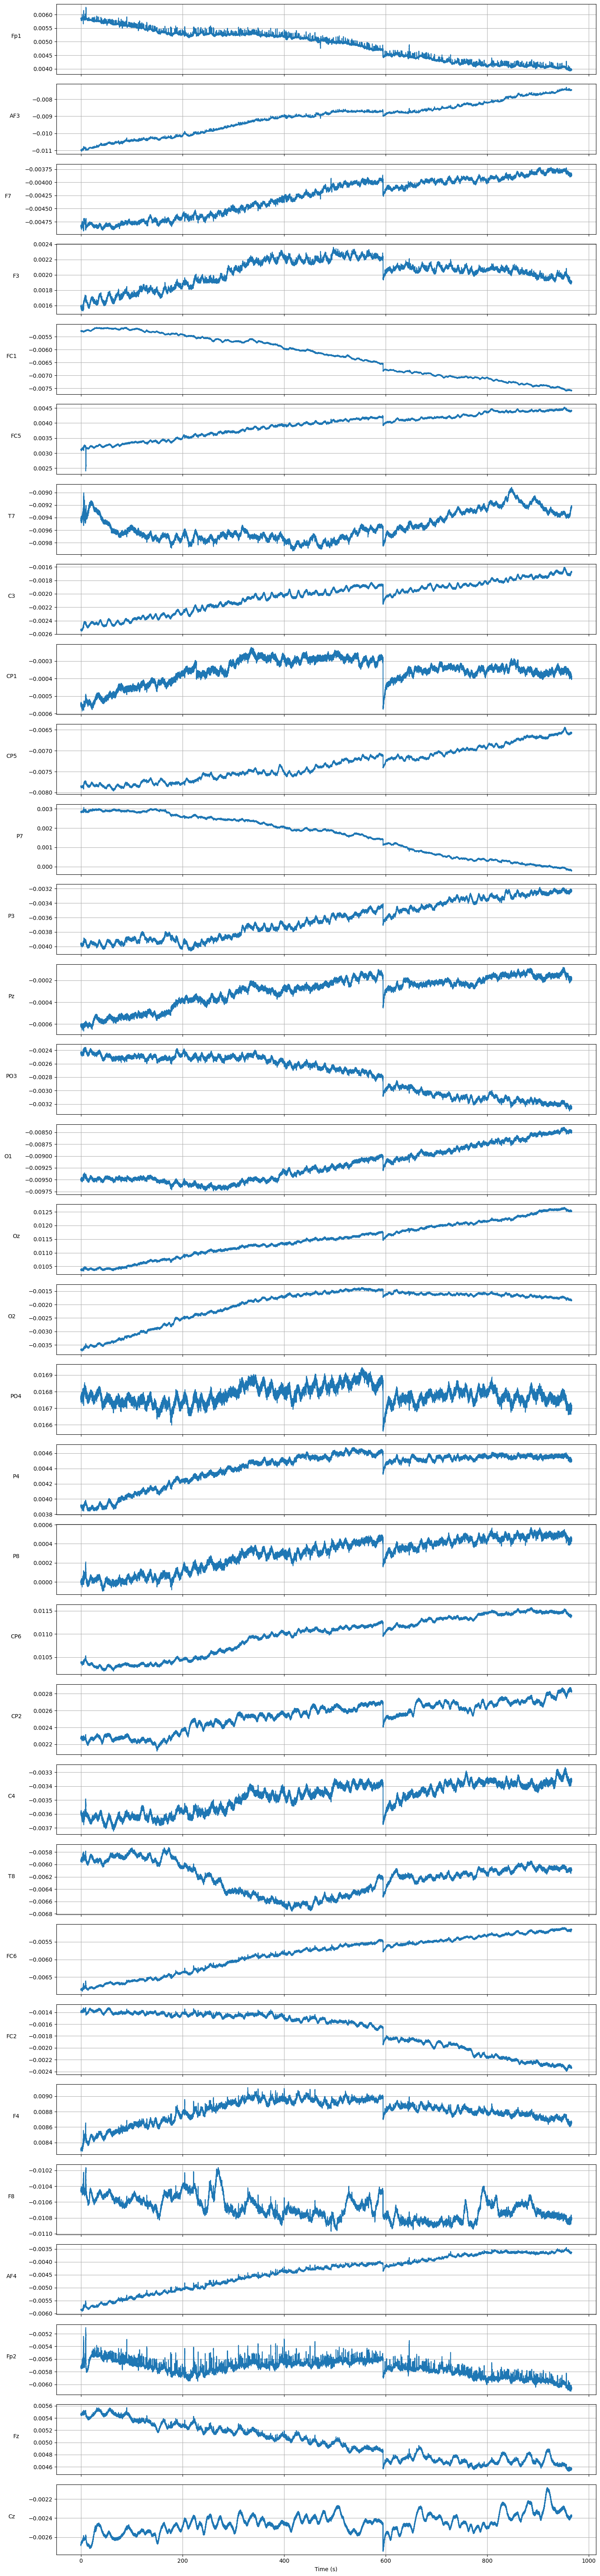

In [ ]:

channel_names = raw_eeg.ch_names
n_channels = len(channel_names) - 15 #for the non-eeg signals
fig, axs = plt.subplots(n_channels, 1, figsize=(15, 2 * n_channels), sharex=True)

for i in range(n_channels):
    axs[i].plot(times, eeg_data[i])
    axs[i].set_ylabel(channel_names[i], rotation=0, labelpad=30)
    axs[i].grid(True)

axs[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

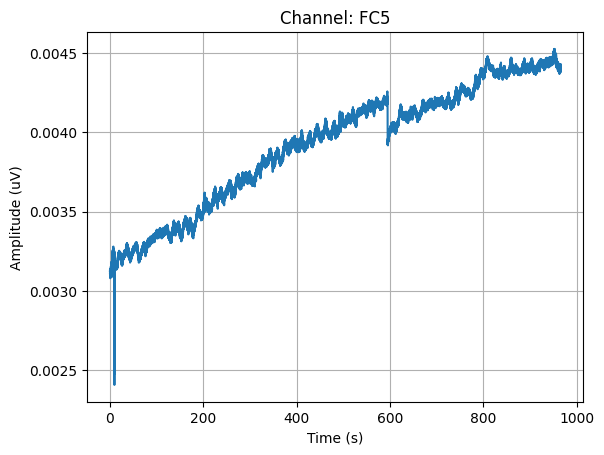

In [ ]:

plt.plot(times, eeg_data[5])  #plot first EEG channel
plt.title(f"Channel: {raw_eeg.ch_names[5]}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (uV)")
plt.grid(True)
plt.show()

In [ ]:
eeg_data[5].dtype

dtype('float64')

In [ ]:
tp9Small.dtype

dtype('float64')

#RAW DEAP DATA PREPROCESSING


##Downsampled DEAP RAW data


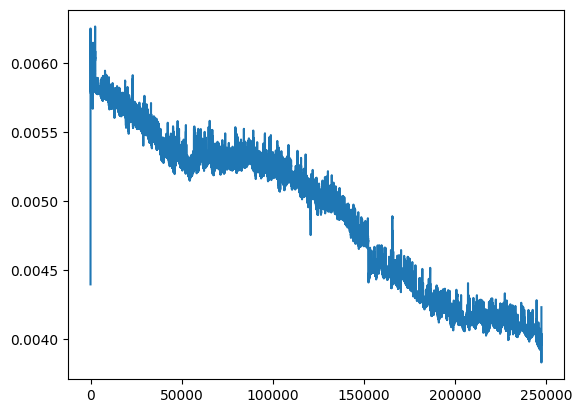

In [ ]:
from scipy.signal import decimate

# pd.Series().interpolate().values
downsampled = decimate(eeg_data[0],2, ftype='fir') #factor of 2 on the DEAP data takes it from 512Hz -> 256Hz (new samplerate = 512Hz/factor)
plt.plot(downsampled)



##Band Filter Pass

In [ ]:
# Bandpass filter between 1 and 50 Hz (standard for EEG viewing)
raw_eeg_bandpass = raw_eeg.copy().filter(l_freq=4.0, h_freq=45.0) #can add in extra feature for bandpass range | range 4 - 45 comes from the bandpass filter that deap use
eeg_dataBPF, times = raw_eeg_bandpass.get_data(return_times=True)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples (1.650 s)



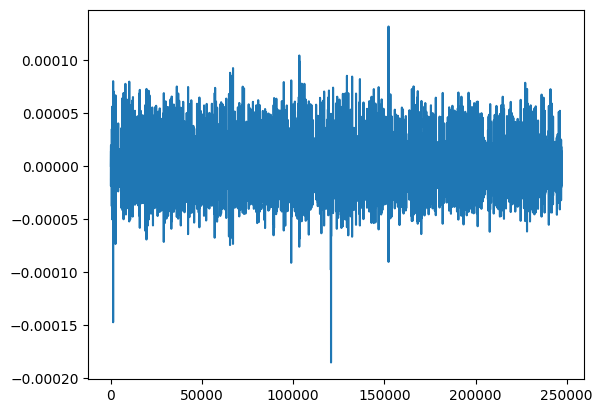

In [ ]:
pd.Series().interpolate().values
downsampled = decimate(eeg_dataBPF[0],2, ftype='fir') #factor of 2 on the DEAP data takes it from 512Hz -> 256Hz (new samplerate = 512Hz/factor)
plt.plot(downsampled)


# ICA

https://mne.tools/stable/generated/mne.preprocessing.ICA.html#footcite-hyvarinen1999

https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html#sphx-glr-auto-examples-preprocessing-muscle-ica-py

In [ ]:
!pip install mne

In [ ]:
import mne
RAND_SEED = 52
N_CHANNELS = n_channels

ica = mne.preprocessing.ICA(N_CHANNELS, random_state=RAND_SEED, max_iter='auto')
ica.fit(raw_eeg_bandpass)
#ica.plot_sources(raw_eeg_bandpass)

Fitting ICA to data using 47 channels (please be patient, this may take a while)
Selecting by number: 32 components


/tmp/ipython-input-2134004059.py:6: RuntimeWarning: Using n_components=32 (resulting in n_components_=32) may lead to an unstable mixing matrix estimation because the ratio between the largest (47) and smallest (4.5e-07) variances is too large (> 1e6); consider setting n_components=0.999999 or an integer <= 10
  ica.fit(raw_eeg_bandpass)


Fitting ICA took 63.9s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,42 iterations on raw data (494592 samples)
ICA components,32
Available PCA components,47
Channel types,eeg
ICA components marked for exclusion,—


Creating RawArray with float64 data, n_channels=32, n_times=494592
    Range : 0 ... 494591 =      0.000 ...   965.998 secs
Ready.


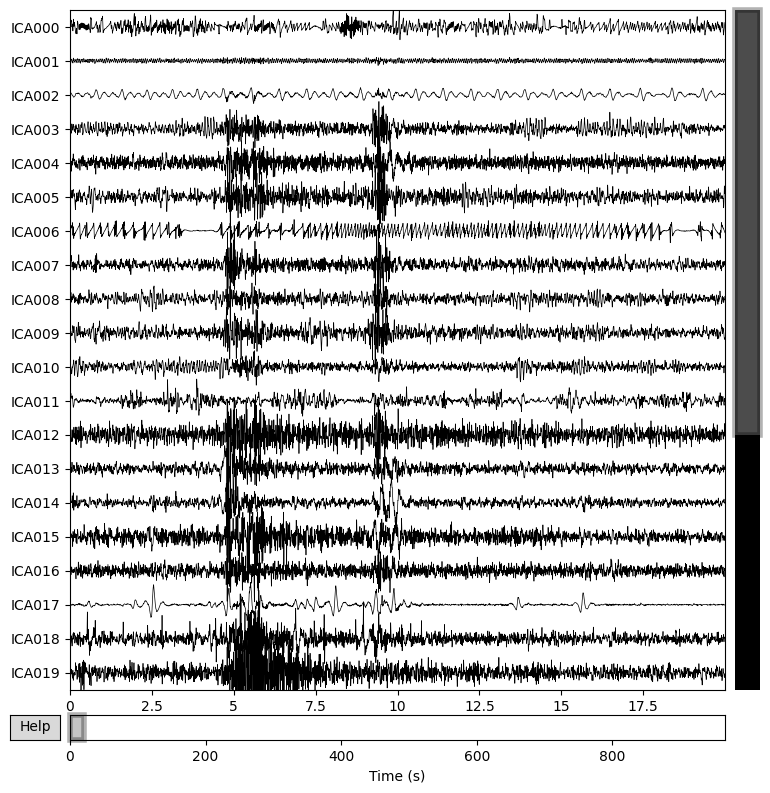

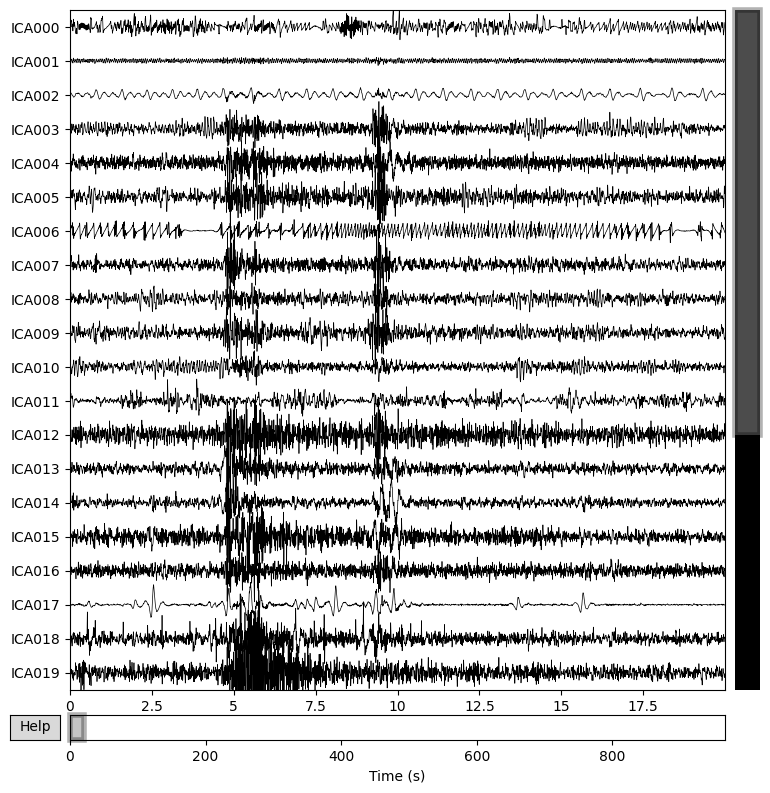

In [ ]:
ica.plot_sources(raw_eeg_bandpass)
